# NusaTripRec - Sistem Rekomendasi Destinasi Wisata Indonesia
### Content-Based Filtering dengan TF-IDF dan Cosine Similarity

Luqman Adiwidya - 24.12.3280

Gcolab ini menjalankan script 'recommender.py' yang ada dalam projek website NusaTripRec. Dikarenakan GColab tidak punya MySQL, maka data dari tiga file CSV dimasukkan ke database SQLite dengan nama tabel yang sama yaitu wisatas dan interaksis. Satu-satunya baris kode asli yang diganti adalah baris from app.database import engine.

Isinya adalah sebagai berikut:
1. Import library, Load dataset, Ringkasan dan visualisasi data, Database pengganti MySQL
2. Kode asli recommender.py
3. TF-IDF & Cosine Similarity
4. Rekomendasi wisata serupa
5. Rekomendasi untuk user
6. Simulasi auto-retrain

## 1. Import Library

In [17]:
import os, re, json, copy, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sqlalchemy import create_engine, text as sql_text
from sqlalchemy.pool import StaticPool


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
print("Library siap digunakan.")

Library siap digunakan.


## 2. Load Dataset

In [4]:
FILES = {
    "wisata": "wisata_indonesia.csv",
    "user": "profil_pengguna.csv",
    "inter": "interaksi_pengguna_wisata.csv"
}

# Upload ketiga file CSV
print("Silakan upload ketiga file CSV:")
uploaded = files.upload()

# Membaca file CSV
read = lambda p: pd.read_csv(p, encoding="utf-8-sig")

wisata = read(FILES["wisata"])
users = read(FILES["user"])
inter = read(FILES["inter"])

# Menampilkan informasi dataset
print("wisata:", wisata.shape,
      "| users:", users.shape,
      "| interaksi:", inter.shape)

wisata.head(3)

Unggah ketiga file CSV:


Saving interaksi_pengguna_wisata.csv to interaksi_pengguna_wisata.csv
Saving profil_pengguna.csv to profil_pengguna.csv
Saving wisata_indonesia.csv to wisata_indonesia.csv
wisata: (30, 12) | users: (15, 8) | interaksi: (151, 7)


,wisata_id,nama_wisata,kabupaten_kota,provinsi,kategori,tags,deskripsi,estimasi_biaya,tingkat_kesulitan,latitude,longitude,gambar
0,1,Candi Borobudur,Magelang,Jawa Tengah,Budaya dan Sejarah,"Candi Buddha, sejarah, arsitektur, warisan budaya, fotografi",Candi Buddha megah dengan relief bersejarah dan pemandangan perbukitan,Rp50.000,Mudah,-7.6079,110.2038,NaN
1,2,Candi Prambanan,Sleman,DI Yogyakarta,Budaya dan Sejarah,"Candi Hindu, sejarah, arsitektur, pertunjukan seni, fotografi",Kompleks candi Hindu dengan arsitektur tinggi dan kisah Ramayana,Rp50.000,Mudah,-7.7520,110.4915,NaN
2,3,Keraton Yogyakarta,Yogyakarta,DI Yogyakarta,Budaya dan Sejarah,"Keraton, budaya Jawa, museum, sejarah, tradisi",Kompleks istana Kesultanan Yogyakarta yang menampilkan budaya Jawa,Rp15.000,Mudah,-7.8053,110.3642,NaN


## 3. Ringkasan dan Visualisasi Data

In [5]:
print("wisata:", wisata.shape, "| users:", users.shape, "| interaksi:", inter.shape)
print("Nilai kosong per tabel:", {n: int(d.isna().sum().sum()) for n, d in [("wisata", wisata), ("users", users), ("interaksi", inter)]},
      "(rating/ulasan kosong = baris bookmark; gambar kosong semua)")
print("ID ganda (wisata, user):", wisata.wisata_id.duplicated().sum(), users.user_id.duplicated().sum(),
      "| ID tidak dikenal (user, wisata):", (~inter.user_id.isin(users.user_id)).sum(), (~inter.wisata_id.isin(wisata.wisata_id)).sum(),
      "| rating di luar 1-5:", ((inter.rating<1)|(inter.rating>5)).sum())


eda = wisata.copy()
eda["biaya_rp"] = eda["estimasi_biaya"].apply(lambda x: int(re.sub(r"[^0-9]", "", str(x)) or 0))
ratings = inter[inter.jenis_interaksi == "rating"].copy()
users["minat_list"] = users["minat_kategori"].str.split(";")

print(f"\nInteraksi: {len(ratings)} rating + {(inter.jenis_interaksi=='bookmark').sum()} bookmark | rata-rata rating {ratings.rating.mean():.2f}")
print("Sebaran rating:", ratings.rating.value_counts().sort_index().to_dict(), "| rating >= 3.0:", int((ratings.rating >= 3).sum()))
print("Kategori wisata:", wisata.kategori.value_counts().to_dict())
print("Minat pengguna :", users.explode("minat_list").minat_list.value_counts().to_dict())

wisata: (30, 12) | users: (15, 8) | interaksi: (151, 7)
Nilai kosong per tabel: {'wisata': 30, 'users': 0, 'interaksi': 122} (rating/ulasan kosong = baris bookmark; gambar kosong semua)
ID ganda (wisata, user): 0 0 | ID tidak dikenal (user, wisata): 0 0 | rating di luar 1-5: 0

Interaksi: 90 rating + 61 bookmark | rata-rata rating 3.84
Sebaran rating: {2.0: 17, 3.0: 12, 4.0: 29, 5.0: 32} | rating >= 3.0: 73
Kategori wisata: {'Budaya dan Sejarah': 9, 'Alam': 9, 'Pantai': 8, 'Keluarga': 3, 'Petualangan': 1}
Minat pengguna : {'Alam': 9, 'Pantai': 6, 'Budaya dan Sejarah': 6, 'Petualangan': 5, 'Keluarga': 3, 'Kuliner': 1}


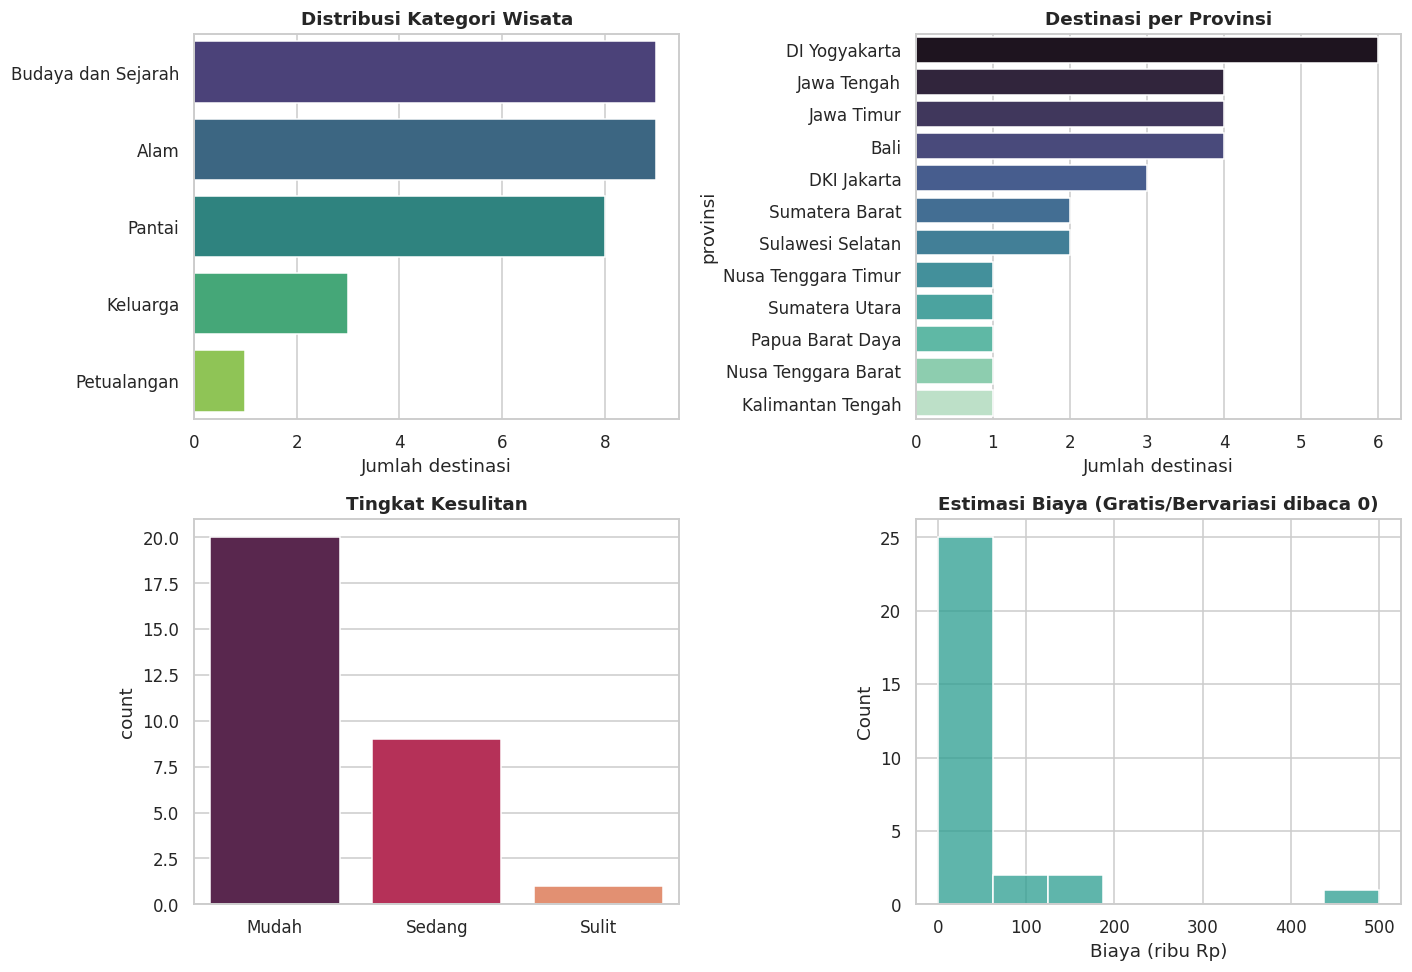

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=eda, y="kategori", order=eda.kategori.value_counts().index, ax=axes[0,0], palette="viridis")
axes[0,0].set_title("Distribusi Kategori Wisata"); axes[0,0].set_xlabel("Jumlah destinasi"); axes[0,0].set_ylabel("")
prov = eda.provinsi.value_counts()
sns.barplot(x=prov.values, y=prov.index, ax=axes[0,1], palette="mako"); axes[0,1].set_title("Destinasi per Provinsi"); axes[0,1].set_xlabel("Jumlah destinasi")
sns.countplot(data=eda, x="tingkat_kesulitan", order=["Mudah","Sedang","Sulit"], ax=axes[1,0], palette="rocket"); axes[1,0].set_title("Tingkat Kesulitan"); axes[1,0].set_xlabel("")
sns.histplot(eda.biaya_rp/1000, bins=8, ax=axes[1,1], color="#2a9d8f"); axes[1,1].set_title("Estimasi Biaya (Gratis/Bervariasi dibaca 0)"); axes[1,1].set_xlabel("Biaya (ribu Rp)")
plt.tight_layout(); plt.savefig("figures/fig01_distribusi_katalog.png", dpi=150); plt.show()

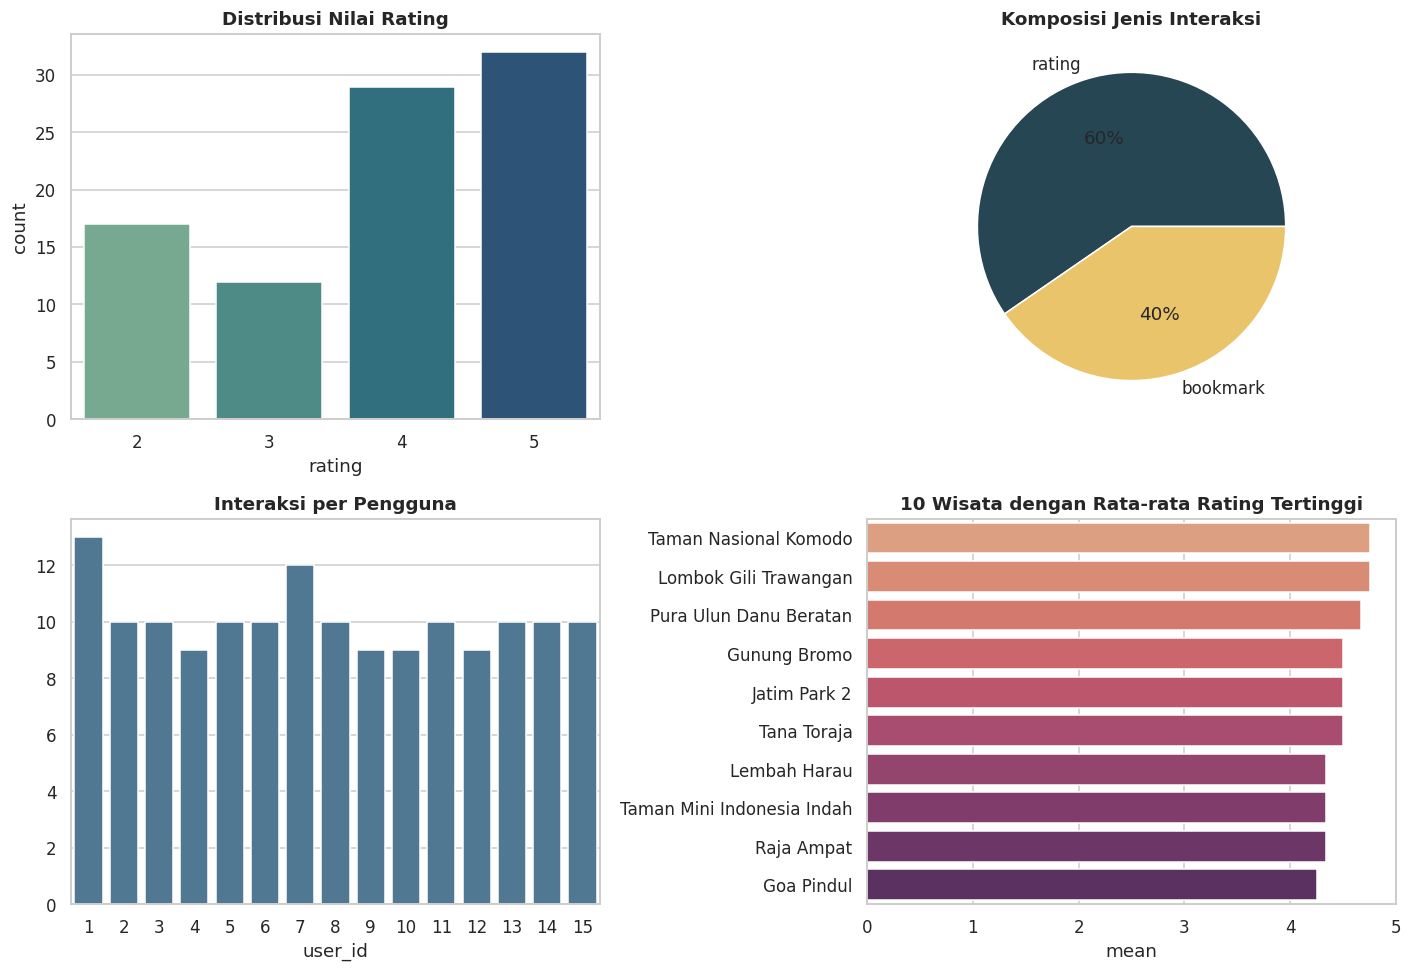

Sparsity matriks user-wisata (rating): 80%


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(x="rating", data=ratings, ax=axes[0,0], palette="crest"); axes[0,0].set_title("Distribusi Nilai Rating"); axes[0,0].set_xticklabels([f"{v:.0f}" for v in sorted(ratings.rating.unique())])
inter.jenis_interaksi.value_counts().plot.pie(autopct="%1.0f%%", ax=axes[0,1], colors=["#264653","#e9c46a"], ylabel=""); axes[0,1].set_title("Komposisi Jenis Interaksi")
pu = inter.groupby("user_id").size(); sns.barplot(x=pu.index, y=pu.values, ax=axes[1,0], color="#457b9d"); axes[1,0].set_title("Interaksi per Pengguna"); axes[1,0].set_xlabel("user_id")
st = ratings.groupby("wisata_id").rating.agg(["mean","count"]).join(wisata.set_index("wisata_id").nama_wisata)
top = st.sort_values(["mean","count"], ascending=False).head(10)
sns.barplot(x=top["mean"], y=top.nama_wisata, ax=axes[1,1], palette="flare"); axes[1,1].set_xlim(0,5); axes[1,1].set_title("10 Wisata dengan Rata-rata Rating Tertinggi"); axes[1,1].set_ylabel("")
plt.tight_layout(); plt.savefig("figures/fig02_distribusi_interaksi.png", dpi=150); plt.show()
sparsity = 1 - ratings[["user_id","wisata_id"]].drop_duplicates().shape[0] / (len(users)*len(wisata))
print(f"Sparsity matriks user-wisata (rating): {sparsity:.0%}")

## 4. Database Pengganti MySQL

In [8]:
engine = create_engine("sqlite://", poolclass=StaticPool, connect_args={"check_same_thread": False})

wisata.to_sql("wisatas", engine, index=False, if_exists="replace")
inter.to_sql("interaksis", engine, index=False, if_exists="replace")

with engine.connect() as conn:
    print("wisatas   :", conn.execute(sql_text("SELECT COUNT(*) FROM wisatas")).scalar(), "baris")
    print("interaksis:", conn.execute(sql_text("SELECT COUNT(*) FROM interaksis")).scalar(), "baris")

wisatas   : 30 baris
interaksis: 151 baris


## 5. Kode Asli `recommender.py`
Ada 1 perbedaan yaitu pada baris import engine yang diganti seperti dijelaskan pada komentar.

In [9]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sqlalchemy import text
# from app.database import engine <- baris yang diganti
import logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class ContentBasedRecommender:
    def __init__(self):
        self.df_wisata = pd.DataFrame()
        self.tfidf_matrix = None
        self.cosine_sim = None
        self.vectorizer = TfidfVectorizer(stop_words=None)

    def load_data_and_train(self):
        """Membaca data dari MySQL & menghitung matriks TF-IDF & Cosine Similarity."""
        logger.info("Memuat data dari database MySQL...")
        query = """
            SELECT
                wisata_id, nama_wisata, deskripsi, kategori,
                provinsi, kabupaten_kota, tingkat_kesulitan, tags
            FROM wisatas
        """
        try:
            with engine.connect() as conn:
                self.df_wisata = pd.read_sql(text(query), conn)
        except Exception as e:
            logger.error(f"Gagal mengambil data dari MySQL: {e}")
            return

        if self.df_wisata.empty:
            logger.warning("Data wisata di database masih kosong!")
            return

        # Preprocessing & Penggabungan Fitur Teks
        self.df_wisata['content_features'] = (
            self.df_wisata['nama_wisata'].fillna('') + ' ' +
            self.df_wisata['kategori'].fillna('') + ' ' +
            self.df_wisata['deskripsi'].fillna('') + ' ' +
            self.df_wisata['tags'].fillna('') + ' ' +
            self.df_wisata['kabupaten_kota'].fillna('') + ' ' +
            self.df_wisata['provinsi'].fillna('')
        ).str.lower()

        # Matriks TF-IDF
        logger.info("Membangun matriks TF-IDF...")
        self.tfidf_matrix = self.vectorizer.fit_transform(self.df_wisata['content_features'])

        # Matriks Cosine Similarity
        logger.info("Menghitung Matriks Cosine Similarity...")
        self.cosine_sim = cosine_similarity(self.tfidf_matrix, self.tfidf_matrix)
        logger.info(f"Recommender Engine Siap! Total data: {len(self.df_wisata)} wisata.")

    def recommend_by_item(self, wisata_id: int, top_n: int = 6):
        """Rekomendasi Wisata Serupa (Item-to-Item Similarity)."""
        if self.df_wisata.empty or self.cosine_sim is None:
            return []

        if wisata_id not in self.df_wisata['wisata_id'].values:
            return []

        idx = self.df_wisata[self.df_wisata['wisata_id'] == wisata_id].index[0]
        sim_scores = list(enumerate(self.cosine_sim[idx]))
        sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
        sim_scores = [item for item in sim_scores if item[0] != idx][:top_n]

        recommendations = []
        for i, score in sim_scores:
            row = self.df_wisata.iloc[i]
            recommendations.append({
                "wisata_id": int(row['wisata_id']),
                "nama_wisata": str(row['nama_wisata']),
                "similarity_score": round(float(score), 4)
            })

        return recommendations

    def recommend_for_user(self, user_id: int, top_n: int = 6):
        """Rekomendasi Personal User Profile (User Profile Vector vs TF-IDF Matrix)."""
        if self.df_wisata.empty or self.tfidf_matrix is None:
            return []

        try:
            # Ambil interaksi user dari tabel interaksis saja (Rating >= 3.0)
            query = text("""
                SELECT wisata_id, rating
                FROM interaksis
                WHERE user_id = :u_id AND rating >= 3.0
            """)

            with engine.connect() as conn:
                user_history = pd.read_sql(query, conn, params={"u_id": user_id})

            # Jika user belum memiliki riwayat interaksi
            if user_history.empty:
                logger.info(f"User #{user_id} belum memiliki riwayat interaksi di tabel interaksis.")
                return []

            history_ids = user_history['wisata_id'].tolist()
            history_indices = self.df_wisata[self.df_wisata['wisata_id'].isin(history_ids)].index.tolist()

            if not history_indices:
                return []

            # Hitung Rata-rata Vektor TF-IDF dari wisata yang disukai user
            user_profile_vector = np.asarray(self.tfidf_matrix[history_indices].mean(axis=0))

            # Hitung Similarity dengan seluruh katalog
            user_sim_scores = cosine_similarity(user_profile_vector, self.tfidf_matrix).flatten()

            sim_scores_list = []
            for idx, score in enumerate(user_sim_scores):
                w_id = self.df_wisata.iloc[idx]['wisata_id']
                if w_id not in history_ids:
                    sim_scores_list.append((idx, score))

            sim_scores_list = sorted(sim_scores_list, key=lambda x: x[1], reverse=True)[:top_n]

            results = []
            for i, score in sim_scores_list:
                row = self.df_wisata.iloc[i]
                results.append({
                    "wisata_id": int(row['wisata_id']),
                    "nama_wisata": str(row['nama_wisata']),
                    "similarity_score": round(float(score), 4)
                })

            return results
        except Exception as e:
            logger.error(f"Error pada recommend_for_user: {e}")
            return []

# Singleton Instance
recommender_engine = ContentBasedRecommender()

## 6. Melatih Model: TF-IDF dan Cosine Similarity

In [10]:
recommender_engine.load_data_and_train()

df_w = recommender_engine.df_wisata
X, S = recommender_engine.tfidf_matrix, recommender_engine.cosine_sim
terms = np.array(recommender_engine.vectorizer.get_feature_names_out())

print("Jumlah wisata             :", len(df_w))
print("Ukuran TF-IDF Matrix      :", X.shape, "(wisata x kata unik)")
print(f"Kepadatan matriks         : {X.nnz/(X.shape[0]*X.shape[1]):.2%}")
print("Ukuran Cosine Sim Matrix  :", S.shape, "| simetris:", np.allclose(S, S.T), "| diagonal = 1:", np.allclose(np.diag(S), 1))
off = S[np.triu_indices_from(S, k=1)]
print(f"Skor antar-wisata -> min {off.min():.3f} | rata-rata {off.mean():.3f} | maks {off.max():.3f}")
print("\nContoh content_features (wisata_id=1):\n", df_w.loc[0, "content_features"])

def top_terms(i, n=6):
    row = X[i].toarray().ravel(); b = row.argsort()[::-1][:n]
    return ", ".join(f"{terms[j]} ({row[j]:.3f})" for j in b)
for i in [0, 4, 7]:
    print(f"\n{df_w.nama_wisata[i]}: {top_terms(i)}")

Jumlah wisata             : 30
Ukuran TF-IDF Matrix      : (30, 266) (wisata x kata unik)
Kepadatan matriks         : 6.69%
Ukuran Cosine Sim Matrix  : (30, 30) | simetris: True | diagonal = 1: True
Skor antar-wisata -> min 0.000 | rata-rata 0.070 | maks 0.438

Contoh content_features (wisata_id=1):
 candi borobudur budaya dan sejarah candi buddha megah dengan relief bersejarah dan pemandangan perbukitan candi buddha, sejarah, arsitektur, warisan budaya, fotografi magelang jawa tengah

Candi Borobudur: candi (0.527), buddha (0.431), sejarah (0.246), budaya (0.225), magelang (0.216), borobudur (0.216)

Pantai Parangtritis: pantai (0.531), pasir (0.397), hamparan (0.244), parangtritis (0.244), atv (0.244), bantul (0.244)

Kawah Ijen: kawah (0.526), api (0.393), biru (0.393), alam (0.214), terkenal (0.197), banyuwangi (0.197)


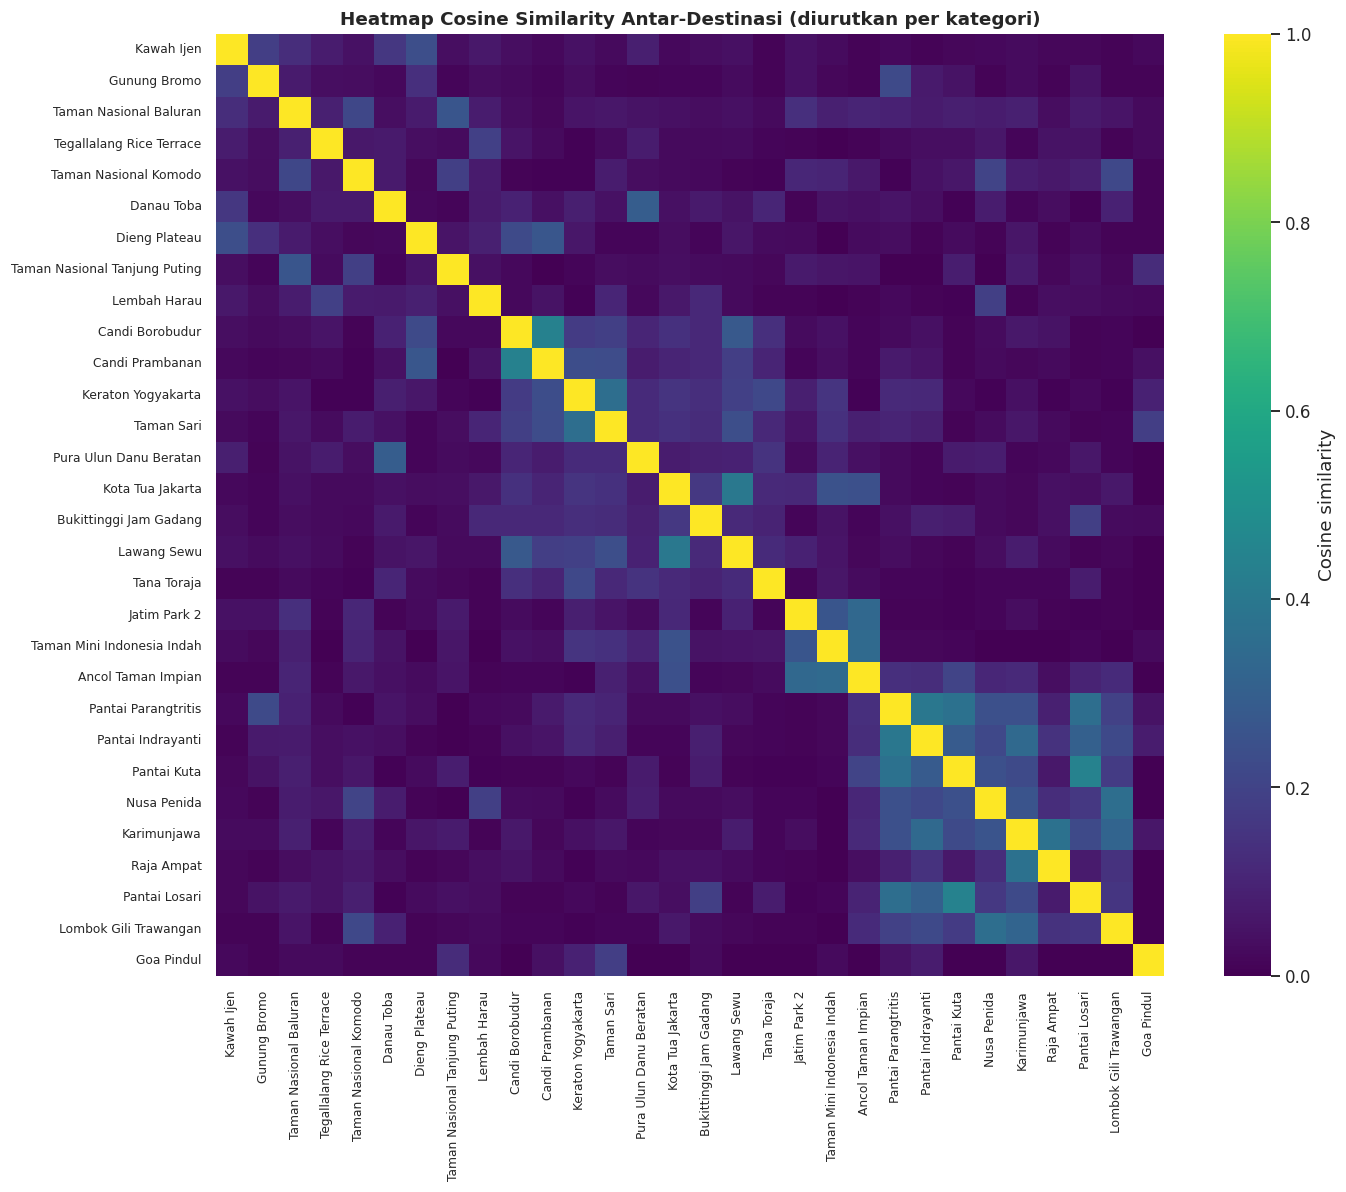

Rata-rata similarity SATU kategori: 0.161 (n=103) | BEDA kategori: 0.042 (n=332)


In [11]:
order_idx = df_w.sort_values(["kategori","wisata_id"]).index
labels = df_w.loc[order_idx, "nama_wisata"]
plt.figure(figsize=(13, 11))
sns.heatmap(S[np.ix_(order_idx, order_idx)], xticklabels=labels, yticklabels=labels, cmap="viridis", vmin=0, vmax=1, cbar_kws={"label": "Cosine similarity"})
plt.title("Heatmap Cosine Similarity Antar-Destinasi (diurutkan per kategori)"); plt.xticks(rotation=90, fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig05_heatmap_cosine_full.png", dpi=150); plt.show()

kat = df_w.kategori.values
same = [S[a,b] for a in range(30) for b in range(a+1,30) if kat[a]==kat[b]]
diff = [S[a,b] for a in range(30) for b in range(a+1,30) if kat[a]!=kat[b]]
print(f"Rata-rata similarity SATU kategori: {np.mean(same):.3f} (n={len(same)}) | BEDA kategori: {np.mean(diff):.3f} (n={len(diff)})")

## 7. Rekomendasi Wisata Serupa

In [12]:
meta = wisata.set_index("wisata_id")[["kategori", "provinsi"]]
def tampil(recs):
    df = pd.DataFrame(recs)
    return df.join(meta, on="wisata_id")[["wisata_id", "nama_wisata", "kategori", "provinsi", "similarity_score"]] if len(df) else df

nama = wisata.set_index("wisata_id").nama_wisata
for wid in [1, 5, 8]:
    print("Mirip dengan:", nama[wid])
    display(tampil(recommender_engine.recommend_by_item(wid)))

Mirip dengan: Candi Borobudur


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,2,Candi Prambanan,Budaya dan Sejarah,DI Yogyakarta,0.4372
1,22,Lawang Sewu,Budaya dan Sejarah,Jawa Tengah,0.2766
2,23,Dieng Plateau,Alam,Jawa Tengah,0.2236
3,4,Taman Sari,Budaya dan Sejarah,DI Yogyakarta,0.1868
4,3,Keraton Yogyakarta,Budaya dan Sejarah,DI Yogyakarta,0.1751
5,17,Kota Tua Jakarta,Budaya dan Sejarah,DKI Jakarta,0.1401


Mirip dengan: Pantai Parangtritis


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,6,Pantai Indrayanti,Pantai,DI Yogyakarta,0.3951
1,12,Pantai Kuta,Pantai,Bali,0.3730
2,26,Pantai Losari,Pantai,Sulawesi Selatan,0.3562
3,24,Karimunjawa,Pantai,Jawa Tengah,0.2445
4,15,Nusa Penida,Pantai,Bali,0.2439
5,9,Gunung Bromo,Alam,Jawa Timur,0.2231


Mirip dengan: Kawah Ijen


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,23,Dieng Plateau,Alam,Jawa Tengah,0.2353
1,9,Gunung Bromo,Alam,Jawa Timur,0.1834
2,20,Danau Toba,Alam,Sumatera Utara,0.1567
3,11,Taman Nasional Baluran,Alam,Jawa Timur,0.1263
4,13,Pura Ulun Danu Beratan,Budaya dan Sejarah,Bali,0.0831
5,14,Tegallalang Rice Terrace,Alam,Bali,0.0757


## 8. Rekomendasi untuk User

In [13]:
def riwayat(uid):
    r = inter[(inter.user_id == uid) & (inter.rating >= 3.0)].merge(wisata[["wisata_id","nama_wisata","kategori"]], on="wisata_id")
    return r[["nama_wisata", "kategori", "rating"]]

uid = 1
print(users.loc[users.user_id==uid, ["user_id","usia","domisili","minat_kategori","preferensi_anggaran","preferensi_kesulitan"]].to_string(index=False))
print("\nWisata yang disukai (rating >= 3):"); display(riwayat(uid))
print("Top-6 rekomendasi:"); display(tampil(recommender_engine.recommend_for_user(uid)))

 user_id  usia   domisili minat_kategori preferensi_anggaran preferensi_kesulitan
       1    21 Yogyakarta    Alam;Pantai            Menengah                Mudah

Wisata yang disukai (rating >= 3):


,nama_wisata,kategori,rating
0,Pantai Parangtritis,Pantai,4.0
1,Pantai Indrayanti,Pantai,4.0
2,Nusa Penida,Pantai,5.0
3,Danau Toba,Alam,4.0
4,Lombok Gili Trawangan,Pantai,5.0
5,Lembah Harau,Alam,4.0


Top-6 rekomendasi:


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,24,Karimunjawa,Pantai,Jawa Tengah,0.3673
1,12,Pantai Kuta,Pantai,Bali,0.3367
2,26,Pantai Losari,Pantai,Sulawesi Selatan,0.3144
3,19,Taman Nasional Komodo,Alam,Nusa Tenggara Timur,0.1882
4,25,Raja Ampat,Pantai,Papua Barat Daya,0.1771
5,18,Ancol Taman Impian,Keluarga,DKI Jakarta,0.1686


In [14]:
for uid in [2, 6, 13]:
    u = users[users.user_id == uid].iloc[0]
    print(f"\n>>> Pengguna {uid} | minat: {u.minat_kategori}")
    display(tampil(recommender_engine.recommend_for_user(uid)))

print("\nUser id 999 (tidak ada riwayat):", recommender_engine.recommend_for_user(999))


>>> Pengguna 2 | minat: Budaya dan Sejarah;Kuliner


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,22,Lawang Sewu,Budaya dan Sejarah,Jawa Tengah,0.4091
1,3,Keraton Yogyakarta,Budaya dan Sejarah,DI Yogyakarta,0.3864
2,13,Pura Ulun Danu Beratan,Budaya dan Sejarah,Bali,0.1874
3,16,Taman Mini Indonesia Indah,Keluarga,DKI Jakarta,0.1778
4,23,Dieng Plateau,Alam,Jawa Tengah,0.1772
5,18,Ancol Taman Impian,Keluarga,DKI Jakarta,0.1237



>>> Pengguna 6 | minat: Alam;Petualangan


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,29,Taman Nasional Tanjung Puting,Alam,Kalimantan Tengah,0.2454
1,15,Nusa Penida,Pantai,Bali,0.1731
2,14,Tegallalang Rice Terrace,Alam,Bali,0.1690
3,9,Gunung Bromo,Alam,Jawa Timur,0.1629
4,4,Taman Sari,Budaya dan Sejarah,DI Yogyakarta,0.1602
5,2,Candi Prambanan,Budaya dan Sejarah,DI Yogyakarta,0.1418



>>> Pengguna 13 | minat: Budaya dan Sejarah;Keluarga


,wisata_id,nama_wisata,kategori,provinsi,similarity_score
0,18,Ancol Taman Impian,Keluarga,DKI Jakarta,0.2958
1,3,Keraton Yogyakarta,Budaya dan Sejarah,DI Yogyakarta,0.2703
2,4,Taman Sari,Budaya dan Sejarah,DI Yogyakarta,0.2568
3,22,Lawang Sewu,Budaya dan Sejarah,Jawa Tengah,0.2533
4,17,Kota Tua Jakarta,Budaya dan Sejarah,DKI Jakarta,0.2525
5,23,Dieng Plateau,Alam,Jawa Tengah,0.2169



User id 999 (tidak ada riwayat): []


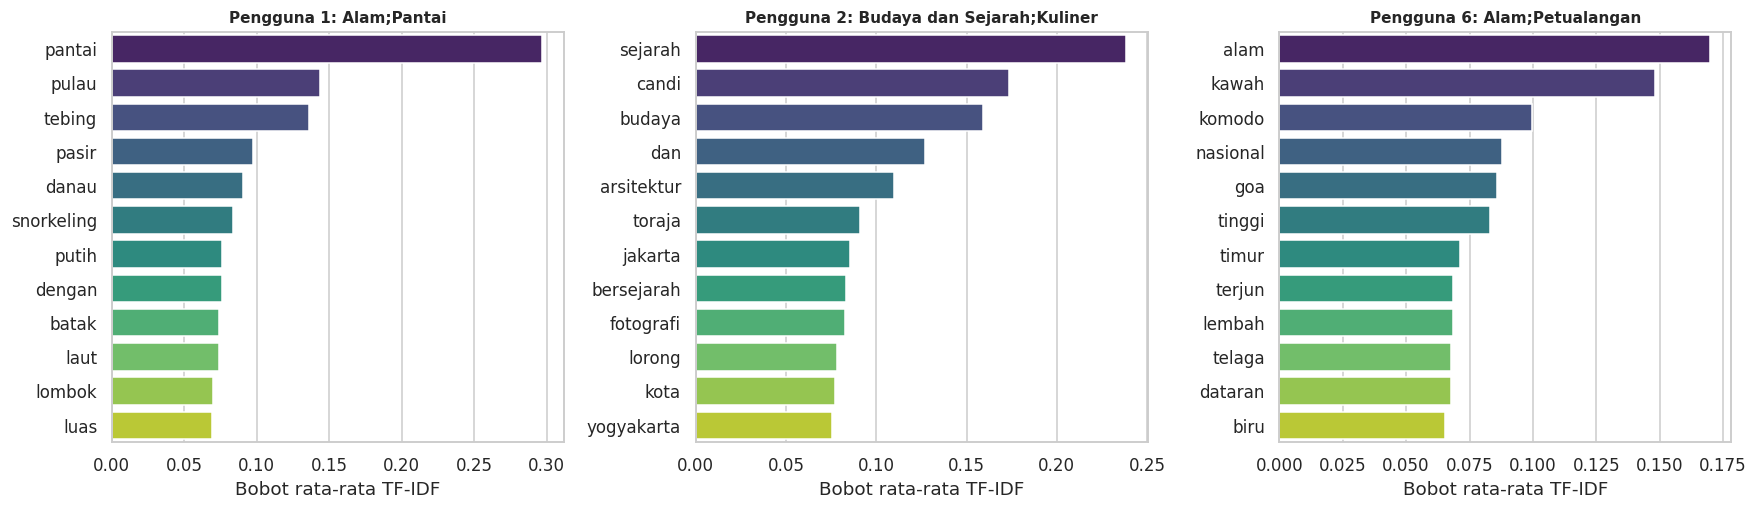

In [15]:
def profil_terms(uid, n=12):
    ids = inter[(inter.user_id==uid) & (inter.rating>=3.0)].wisata_id
    idx = df_w[df_w.wisata_id.isin(ids)].index.tolist()
    p = np.asarray(X[idx].mean(axis=0)).ravel(); b = p.argsort()[::-1][:n]
    return terms[b], p[b]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, uid in zip(axes, [1, 2, 6]):
    t, v = profil_terms(uid); sns.barplot(x=v, y=t, ax=ax, palette="viridis")
    ax.set_title(f"Pengguna {uid}: " + users.loc[users.user_id==uid,'minat_kategori'].iloc[0], fontsize=10); ax.set_xlabel("Bobot rata-rata TF-IDF")
plt.tight_layout(); plt.savefig("figures/fig08_user_profile_terms.png", dpi=150); plt.show()

## 9. Simulasi Auto-Retrain

In [16]:
uid = 4
sebelum = [r["nama_wisata"] for r in recommender_engine.recommend_for_user(uid)]

with engine.begin() as c:
    c.execute(sql_text("INSERT INTO interaksis (interaksi_id, user_id, wisata_id, jenis_interaksi, rating, ulasan, tanggal_interaksi) "
                       "VALUES (9999, 4, 8, 'rating', 5.0, 'Simulasi rating baru', '2026-11-18')"))
recommender_engine.load_data_and_train()
sesudah = [r["nama_wisata"] for r in recommender_engine.recommend_for_user(uid)]
print("\nSebelum rating baru:", sebelum); print("Sesudah rating baru :", sesudah)

with engine.begin() as c:
    c.execute(sql_text("DELETE FROM interaksis WHERE interaksi_id = 9999"))
recommender_engine.load_data_and_train()


Sebelum rating baru: ['Lawang Sewu', 'Taman Sari', 'Jatim Park 2', 'Keraton Yogyakarta', 'Dieng Plateau', 'Bukittinggi Jam Gadang']
Sesudah rating baru : ['Lawang Sewu', 'Taman Sari', 'Jatim Park 2', 'Dieng Plateau', 'Keraton Yogyakarta', 'Pura Ulun Danu Beratan']
